In [5]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras import utils
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
%matplotlib inline

In [6]:
(x_train_org, y_train_org), (x_test_org, y_test_org) = mnist.load_data()

In [7]:
print('Размер обучающей выборки - картинок -', x_train_org.shape)
print('Размер обучающей выборки - верных ответов -', y_train_org.shape)
print('Размер тестовой выборки - картинок -', x_test_org.shape)
print('Размер тестовой выборки - верных ответов -', y_test_org.shape)

Размер обучающей выборки - картинок - (60000, 28, 28)
Размер обучающей выборки - верных ответов - (60000,)
Размер тестовой выборки - картинок - (10000, 28, 28)
Размер тестовой выборки - верных ответов - (10000,)


Визуализация изображения датасета

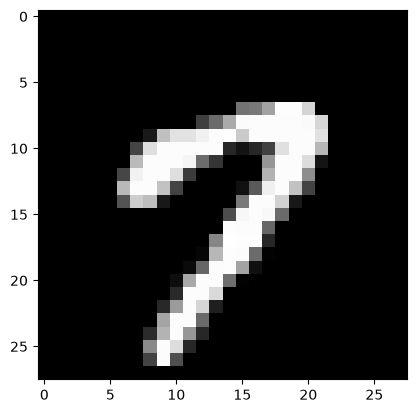

In [8]:
n = 15 #Номер картинки

#Image.fromarray - создание картинки по массиву
#.convert('RGBA') - преобразование в RGBA формат
plt.imshow(Image.fromarray(x_train_org[n]).convert('RGBA'))
plt.show()

In [9]:
#Меняем формат входных картинок с 28х28 на 784х1
x_train = x_train_org.reshape(60000, 784)
x_test = x_test_org.reshape(10000, 784)

In [10]:
print('Размер обучающей выборки - картинок -', x_train.shape)
print('Размер тестовой выборки - картинок -', x_test.shape)

Размер обучающей выборки - картинок - (60000, 784)
Размер тестовой выборки - картинок - (10000, 784)


Нормализация данных

In [11]:
x_train = x_train.astype('float32')
x_train = x_train / 255
x_test = x_test.astype('float32')
x_test = x_test / 255

Преобразуем метки (эталон выхода) в формат one hot encoding

In [12]:
y_train = utils.to_categorical(y_train_org, 10)
y_test = utils.to_categorical(y_test_org, 10)

In [13]:
print(y_train_org[n])
print(y_train[n])

7
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


Создание полносвязной нейронной сети

In [14]:
model = Sequential()

model.add(Dense(800, input_dim=784, activation="relu"))
model.add(Dense(400, activation="relu"))

model.add(Dense(10, activation="softmax"))

c:\Users\фвьшт\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

#Вывод структуры нейронки
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 800)            │       628,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 400)            │       320,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         4,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 952,410 (3.63 MB)

 Trainable params: 952,410 (3.63 MB)

 Non-trainable params: 0 (0.00 B)

None


In [16]:
model.fit(x_train, y_train, batch_size=200, epochs=20, verbose=1, validation_split=0.2)

Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9249 - loss: 0.2552 - val_accuracy: 0.9621 - val_loss: 0.1237
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9729 - loss: 0.0903 - val_accuracy: 0.9712 - val_loss: 0.0898
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9824 - loss: 0.0554 - val_accuracy: 0.9760 - val_loss: 0.0791
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9885 - loss: 0.0353 - val_accuracy: 0.9767 - val_loss: 0.0772
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9917 - loss: 0.0267 - val_accuracy: 0.9796 - val_loss: 0.0717
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9948 - loss: 0.0165 - val_accuracy: 0.9792 - val_loss: 0.0786
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9947 - loss: 0.0150 - val_accuracy: 0.9789 - val_loss: 0.0846
Epoch 8/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9948 - loss: 0.0156 - val_accuracy: 0.

In [17]:
# Сохранение ПНС
model.save("mnist_dense.keras")

Используем сеть для распознавания рукописных цифр

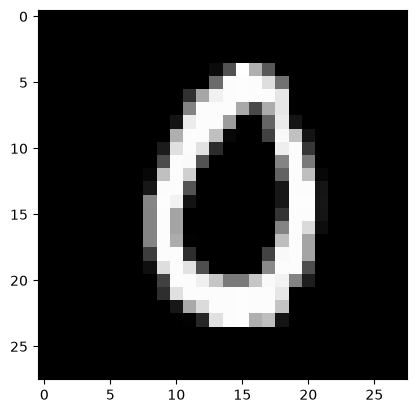

In [18]:
n_rec = 1001

plt.imshow(Image.fromarray(x_test_org[n_rec]).convert('RGBA'))
plt.show()

In [19]:
x = x_test[n_rec]
print(x.shape)

(784,)


In [20]:
#Добавляем одну размерность в конце, чтобы нейронка могла распознать пример
x = np.expand_dims(x, axis=0)
print(x.shape)

(1, 784)


In [21]:
prediction = model.predict(x)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


In [22]:
print(prediction)
print(prediction.shape)

[[1.0000000e+00 3.2862761e-14 7.6403377e-11 6.9396255e-16 8.7730778e-12
  9.6340968e-15 7.6528471e-12 1.7103393e-11 2.6262278e-17 1.9290448e-10]]
(1, 10)


In [23]:
prediction = np.argmax(prediction)
print(prediction)

0


In [24]:
#выводим правильный ответ, для сравнения
print(y_test_org[n_rec])

0


In [25]:
pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step


In [26]:
pred_arg = np.argmax(pred, axis=1)
print(pred_arg[:20])
print(y_test_org[:20])

true_predicted = pred_arg == y_test_org
print(true_predicted[:20])

[7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4]
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
[ True  True  True  True  True  True  True  True False  True  True  True
  True  True  True  True  True  True  True  True]


In [27]:
# Точность НС как отношение кол-ва правильно предсказанных примеров ко всем примерам в тестовой выборке
test_acc = true_predicted.sum() / true_predicted.shape[0]
print(test_acc)

0.9812


In [28]:
# То же самое, но с помощью метода evaluate
test_acc_ev = model.evaluate(x_test, y_test)
print(test_acc_ev)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9812 - loss: 0.0938
[0.09378445148468018, 0.9811999797821045]


ПРОВЕРКА РАЗНЫХ ГИПЕРПАРАМЕТРОВ

In [29]:
def build_and_train_model(model_name, layers, epochs=20, batch_size=200):
    print(f"\n--- Обучение модели: {model_name} ---")

    model = Sequential()
    # Добавляем Input layer, чтобы избежать warning'ов
    model.add(Input(shape=(784,)))
    for layer in layers:
        model.add(layer)

    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

    history = model.fit(x_train, y_train,
                        batch_size=batch_size,
                        epochs=epochs,
                        verbose=0,
                        validation_split=0.2)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Модель: {model_name}', fontsize=14, fontweight='bold')

    epochs_range = range(1, len(history.history['loss']) + 1)

    # График точности
    axes[0].plot(epochs_range, history.history['accuracy'],
                 label='Train', marker='o', markersize=4)
    axes[0].plot(epochs_range, history.history['val_accuracy'],
                 label='Validation', marker='s', markersize=4)
    axes[0].set_title('Accuracy (Точность)')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # График функции потерь
    axes[1].plot(epochs_range, history.history['loss'],
                 label='Train', marker='o', markersize=4)
    axes[1].plot(epochs_range, history.history['val_loss'],
                 label='Validation', marker='s', markersize=4)
    axes[1].set_title('Loss (Функция потерь)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model, history

In [30]:

model_1_layers = [
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
]

model_2_layers = [
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')
]

model_3_layers = [
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
]

model_4_layers = [
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
]


--- Обучение модели: Base (128) ---


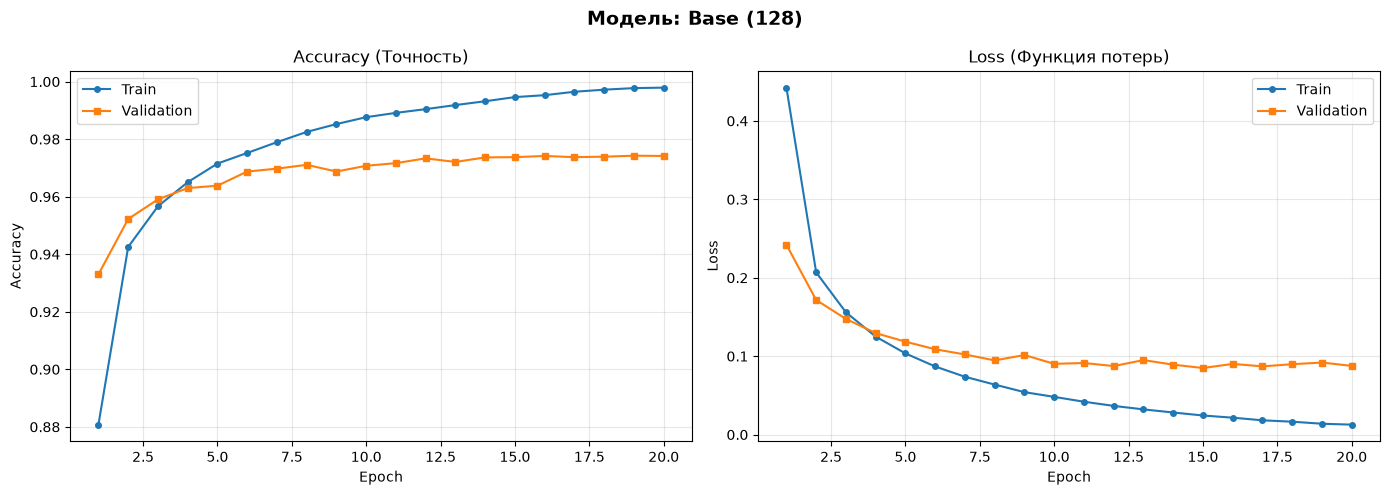


--- Обучение модели: Wide (512) ---


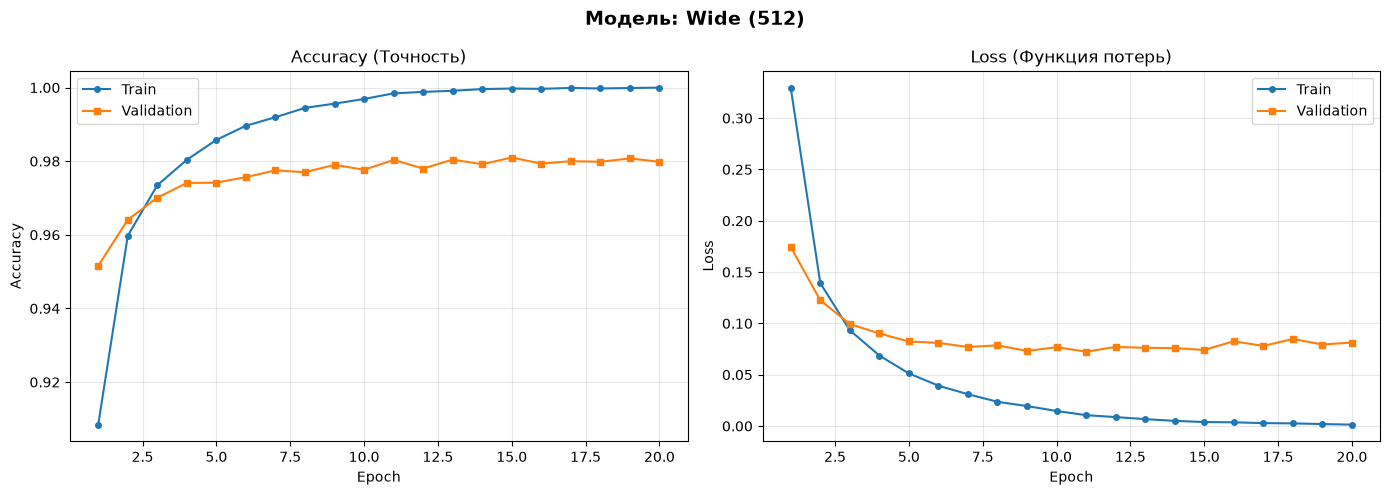


--- Обучение модели: Deep (256-128) ---


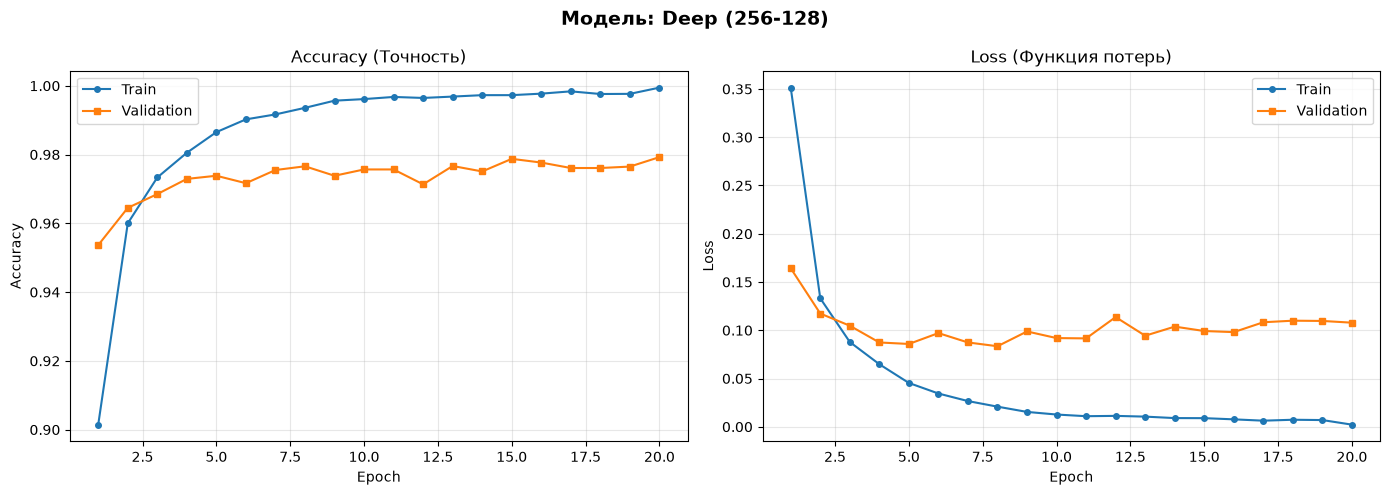


--- Обучение модели: Dropout (512-256) ---


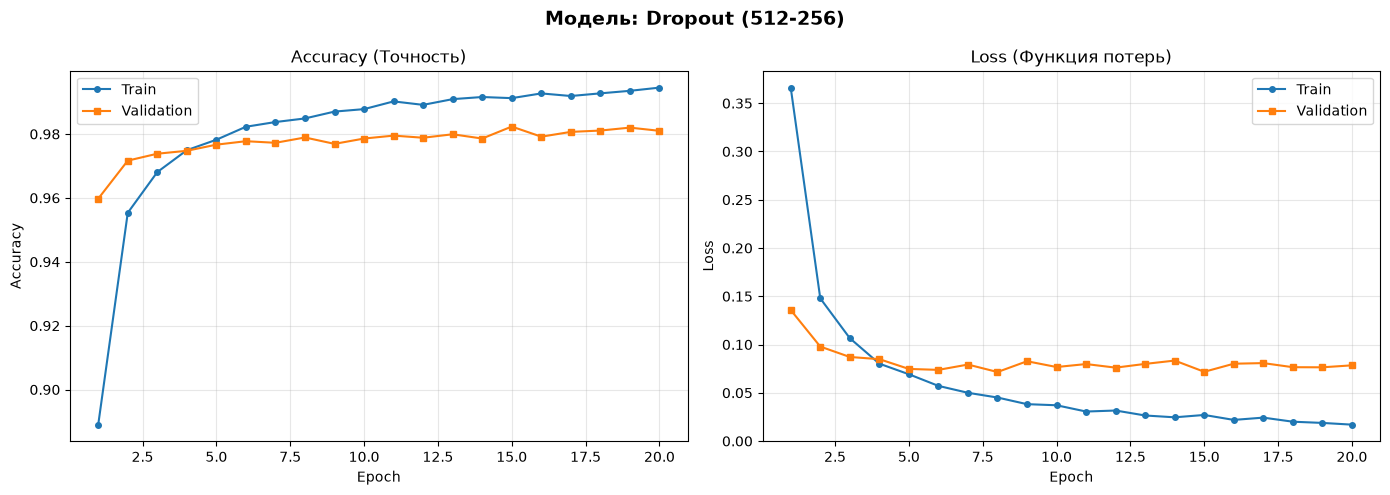

In [31]:
models_info = {
    "Base (128)": model_1_layers,
    "Wide (512)": model_2_layers,
    "Deep (256-128)": model_3_layers,
    "Dropout (512-256)": model_4_layers
}

results = []

for name, layers in models_info.items():
    model2, history = build_and_train_model(name, layers)

    loss, accuracy = model2.evaluate(x_test, y_test, verbose=0)

    num_params = model2.count_params()

    results.append({
        "Model": name,
        "Test Accuracy": accuracy,
        "Test Loss": loss,
        "Parameters": num_params,
        "Epochs": len(history.history['loss'])
    }
)

In [32]:
import pandas as pd

df_results = pd.DataFrame(results)
df_results['Test Accuracy'] = df_results['Test Accuracy'].map('{:.4f}'.format)
df_results['Test Loss'] = df_results['Test Loss'].map('{:.4f}'.format)

print("\n\n--- Сравнение архитектур нейронных сетей ---")
print(df_results.to_string(index=False))

df_results_sorted = df_results.sort_values(by='Test Accuracy', ascending=False)
print("\n--- Топ моделей по точности ---")
print(df_results_sorted.to_string(index=False))



--- Сравнение архитектур нейронных сетей ---
            Model Test Accuracy Test Loss  Parameters  Epochs
       Base (128)        0.9767    0.0769      101770      20
       Wide (512)        0.9812    0.0680      407050      20
   Deep (256-128)        0.9804    0.0943      235146      20
Dropout (512-256)        0.9842    0.0605      535818      20

--- Топ моделей по точности ---
            Model Test Accuracy Test Loss  Parameters  Epochs
Dropout (512-256)        0.9842    0.0605      535818      20
       Wide (512)        0.9812    0.0680      407050      20
   Deep (256-128)        0.9804    0.0943      235146      20
       Base (128)        0.9767    0.0769      101770      20


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras import utils
import numpy as np

def build_and_train_model(model_name, layers, epochs=20, batch_size=200):
    print(f"\n--- Обучение модели: {model_name} (epochs={epochs}, batch_size={batch_size}) ---")

    model = Sequential()
    model.add(Input(shape=(784,)))
    for layer in layers:
        model.add(layer)

    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

    history = model.fit(x_train, y_train,
                        batch_size=batch_size,
                        epochs=epochs,
                        verbose=1,
                        validation_split=0.2)

    # Оценка на тестовых данных
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Модель: {model_name}\n(epochs={epochs}, batch_size={batch_size})', fontsize=14, fontweight='bold')

    epochs_range = range(1, len(history.history['loss']) + 1)

    # График точности
    axes[0].plot(epochs_range, history.history['accuracy'], label='Train', marker='o', markersize=4)
    axes[0].plot(epochs_range, history.history['val_accuracy'], label='Validation', marker='s', markersize=4)
    axes[0].set_title('Accuracy (Точность)')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # График функции потерь
    axes[1].plot(epochs_range, history.history['loss'], label='Train', marker='o', markersize=4)
    axes[1].plot(epochs_range, history.history['val_loss'], label='Validation', marker='s', markersize=4)
    axes[1].set_title('Loss (Функция потерь)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model, history, loss, accuracy

In [34]:
# Определяем словарь с архитектурами для тестирования
models_to_test = {
    # 1. Базовая модель (1 скрытый слой)
    "Base (1 hidden)": [
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ],
    # 2. Широкая модель (1 скрытый слой, много нейронов)
    "Wide (1 hidden)": [
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ],
    # 3. Глубокая модель (2 скрытых слоя)
    "Deep (2 hidden)": [
        Dense(256, activation='relu'),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ],
    # 4. Модель с регуляризацией (Dropout)
    "Dropout (2 hidden)": [
        Dense(512, activation='relu'),
        Dropout(0.3),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(10, activation='softmax')
    ],
    # 5. Очень широкая модель (для проверки 1200 нейронов)
    "Very Wide (1200)": [
        Dense(1200, activation='relu'),
        Dense(10, activation='softmax')
    ]
}

ЭКСПЕРИМЕНТ 1: Сравнение архитектур (20 эпох, batch_size=200)

--- Обучение модели: Base (1 hidden) (epochs=20, batch_size=200) ---
Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8820 - loss: 0.4378 - val_accuracy: 0.9393 - val_loss: 0.2270
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9427 - loss: 0.2051 - val_accuracy: 0.9516 - val_loss: 0.1781
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9566 - loss: 0.1539 - val_accuracy: 0.9582 - val_loss: 0.1491
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9654 - loss: 0.1224 - val_accuracy: 0.9624 - val_loss: 0.1297
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9715 - loss: 0.1013 - val_accuracy: 0.9676 - val_loss: 0.1141
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9756 - loss: 0.0858 - val_accuracy: 0.9681 - val_loss: 0.1105
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9793 - loss: 0.0727 - val_accuracy

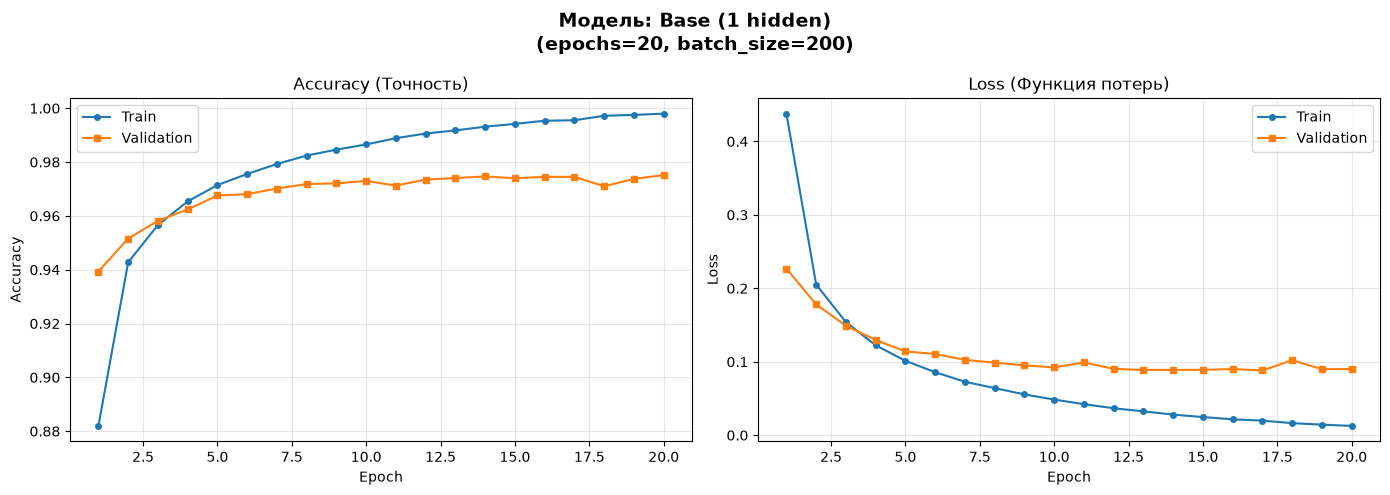


--- Обучение модели: Wide (1 hidden) (epochs=20, batch_size=200) ---
Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9059 - loss: 0.3375 - val_accuracy: 0.9494 - val_loss: 0.1776
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9592 - loss: 0.1436 - val_accuracy: 0.9631 - val_loss: 0.1254
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9728 - loss: 0.0961 - val_accuracy: 0.9715 - val_loss: 0.1023
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9801 - loss: 0.0695 - val_accuracy: 0.9726 - val_loss: 0.0894
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9854 - loss: 0.0534 - val_accuracy: 0.9744 - val_loss: 0.0854
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9891 - loss: 0.0405 - val_accuracy: 0.9745 - val_loss: 0.0797
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9920 - loss: 0.0312 - val_accuracy: 0.9757 - val_loss: 0.0746
Epoch 8/20
240/240 ━━━━━━━━━━━━━━━

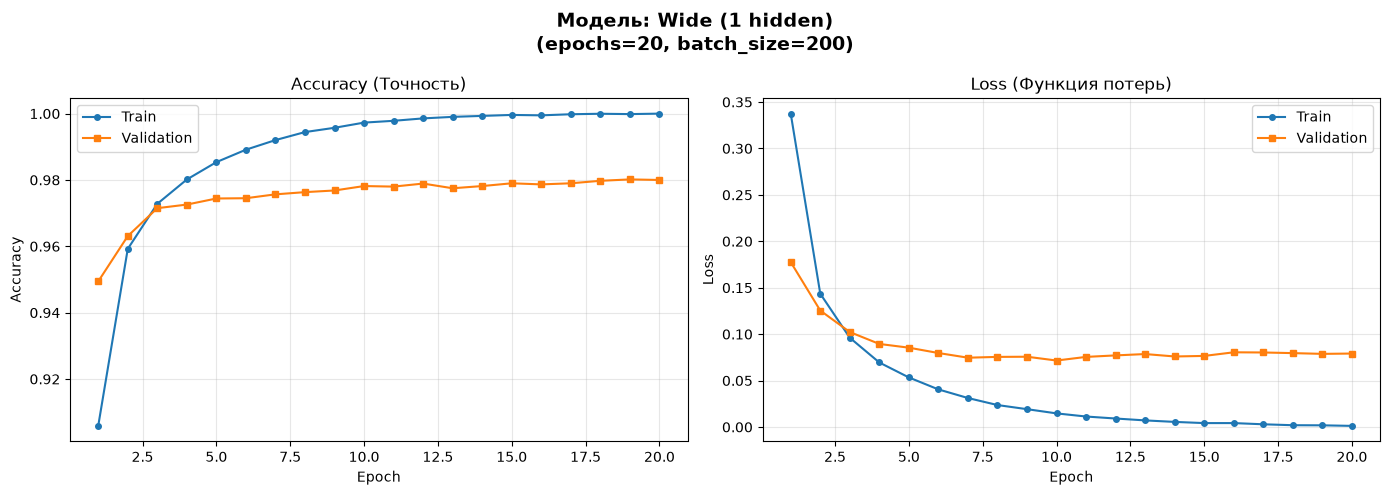


--- Обучение модели: Deep (2 hidden) (epochs=20, batch_size=200) ---
Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9010 - loss: 0.3456 - val_accuracy: 0.9517 - val_loss: 0.1631
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9618 - loss: 0.1304 - val_accuracy: 0.9655 - val_loss: 0.1165
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9747 - loss: 0.0876 - val_accuracy: 0.9730 - val_loss: 0.0950
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9810 - loss: 0.0630 - val_accuracy: 0.9718 - val_loss: 0.0931
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9862 - loss: 0.0462 - val_accuracy: 0.9747 - val_loss: 0.0865
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9886 - loss: 0.0368 - val_accuracy: 0.9750 - val_loss: 0.0860
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9923 - loss: 0.0263 - val_accuracy: 0.9718 - val_loss: 0.0942
Epoch 8/20
240/240 ━━━━━━━━━━━━━━━

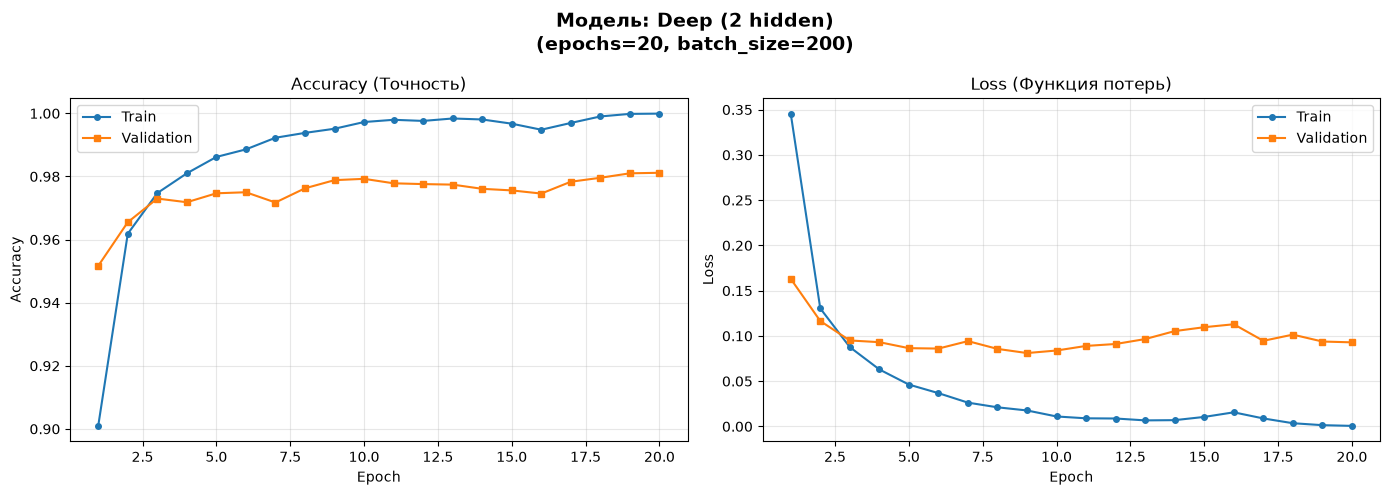


--- Обучение модели: Dropout (2 hidden) (epochs=20, batch_size=200) ---
Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8929 - loss: 0.3610 - val_accuracy: 0.9595 - val_loss: 0.1406
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9557 - loss: 0.1466 - val_accuracy: 0.9684 - val_loss: 0.1049
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9691 - loss: 0.1029 - val_accuracy: 0.9728 - val_loss: 0.0895
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9739 - loss: 0.0844 - val_accuracy: 0.9762 - val_loss: 0.0861
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9789 - loss: 0.0671 - val_accuracy: 0.9790 - val_loss: 0.0749
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9818 - loss: 0.0557 - val_accuracy: 0.9786 - val_loss: 0.0736
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9840 - loss: 0.0506 - val_accuracy: 0.9790 - val_loss: 0.0753
Epoch 8/20
240/240 ━━━━━━━━━━━━

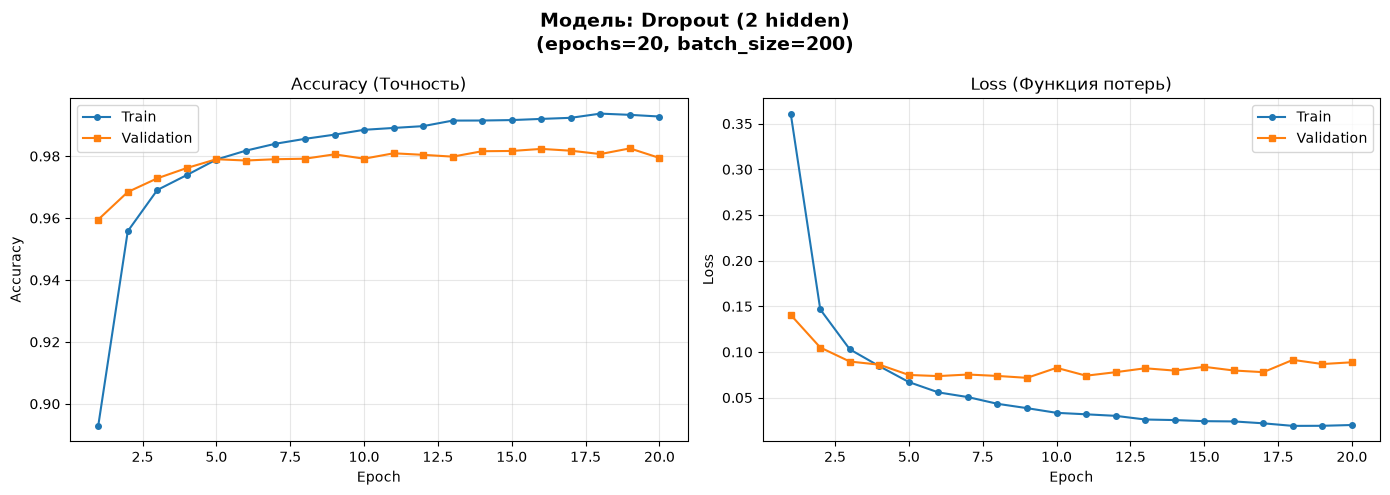


--- Обучение модели: Very Wide (1200) (epochs=20, batch_size=200) ---
Epoch 1/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9146 - loss: 0.2926 - val_accuracy: 0.9567 - val_loss: 0.1520
Epoch 2/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9668 - loss: 0.1134 - val_accuracy: 0.9677 - val_loss: 0.1043
Epoch 3/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9779 - loss: 0.0735 - val_accuracy: 0.9707 - val_loss: 0.0927
Epoch 4/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9862 - loss: 0.0492 - val_accuracy: 0.9753 - val_loss: 0.0825
Epoch 5/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9900 - loss: 0.0357 - val_accuracy: 0.9770 - val_loss: 0.0782
Epoch 6/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9936 - loss: 0.0247 - val_accuracy: 0.9812 - val_loss: 0.0658
Epoch 7/20
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9960 - loss: 0.0175 - val_accuracy: 0.9797 - val_loss: 0.0709
Epoch 8/20
240/240 ━━━━━━━━━━━━━━

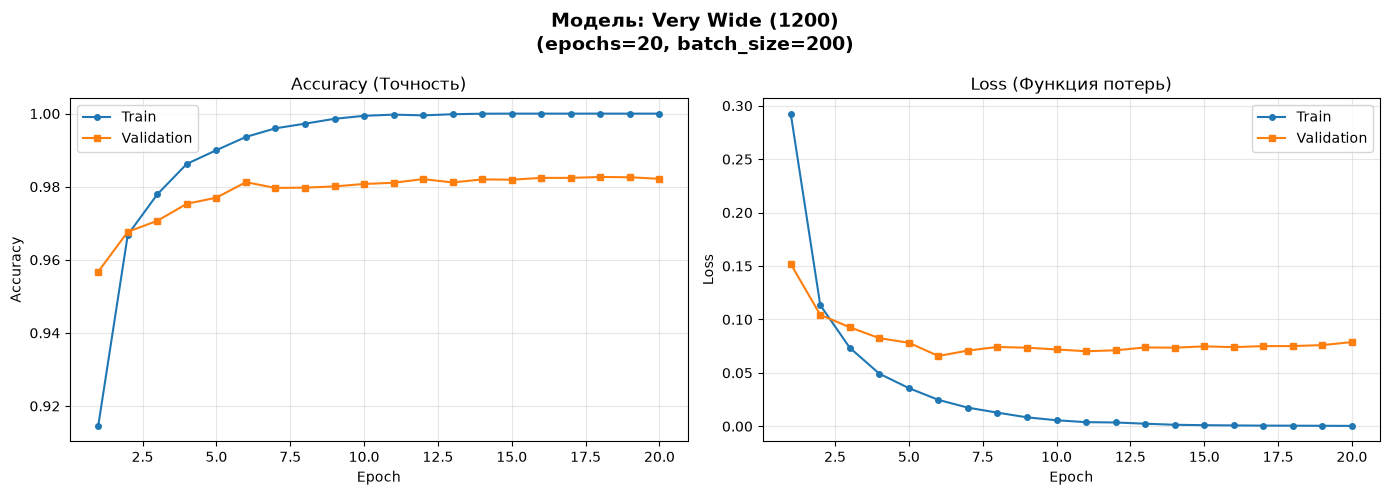

\ЭКСПЕРИМЕНТ 2: Влияние количества эпох (на примере Wide модели)

--- Обучение модели: Wide - 10 epochs (epochs=10, batch_size=200) ---
Epoch 1/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9981 - loss: 0.0066 - val_accuracy: 0.9784 - val_loss: 0.0850
Epoch 2/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9993 - loss: 0.0037 - val_accuracy: 0.9791 - val_loss: 0.0828
Epoch 3/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9999 - loss: 0.0013 - val_accuracy: 0.9797 - val_loss: 0.0848
Epoch 4/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 9.0600e-04 - val_accuracy: 0.9810 - val_loss: 0.0814
Epoch 5/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9764 - val_loss: 0.1051
Epoch 6/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9939 - loss: 0.0186 - val_accuracy: 0.9793 - val_loss: 0.0868
Epoch 7/10
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9997 - loss: 0.0023 - val_

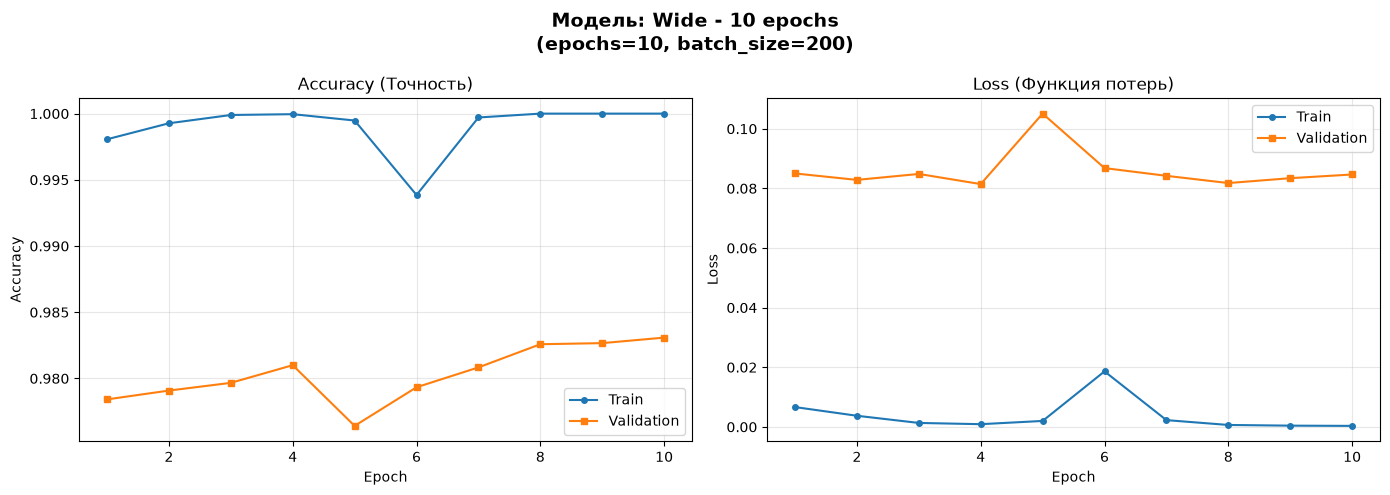


--- Обучение модели: Wide - 15 epochs (epochs=15, batch_size=200) ---
Epoch 1/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9992 - loss: 0.0030 - val_accuracy: 0.9803 - val_loss: 0.0926
Epoch 2/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9994 - loss: 0.0024 - val_accuracy: 0.9804 - val_loss: 0.0908
Epoch 3/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 1.0000 - loss: 4.3517e-04 - val_accuracy: 0.9815 - val_loss: 0.0927
Epoch 4/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 1.0000 - loss: 1.9455e-04 - val_accuracy: 0.9817 - val_loss: 0.0916
Epoch 5/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 1.0000 - loss: 1.4734e-04 - val_accuracy: 0.9822 - val_loss: 0.0932
Epoch 6/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 1.2238e-04 - val_accuracy: 0.9819 - val_loss: 0.0935
Epoch 7/15
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.0948e-04 - val_accuracy: 0.9817 - val_loss: 0.0936
Epoch 8/15
24

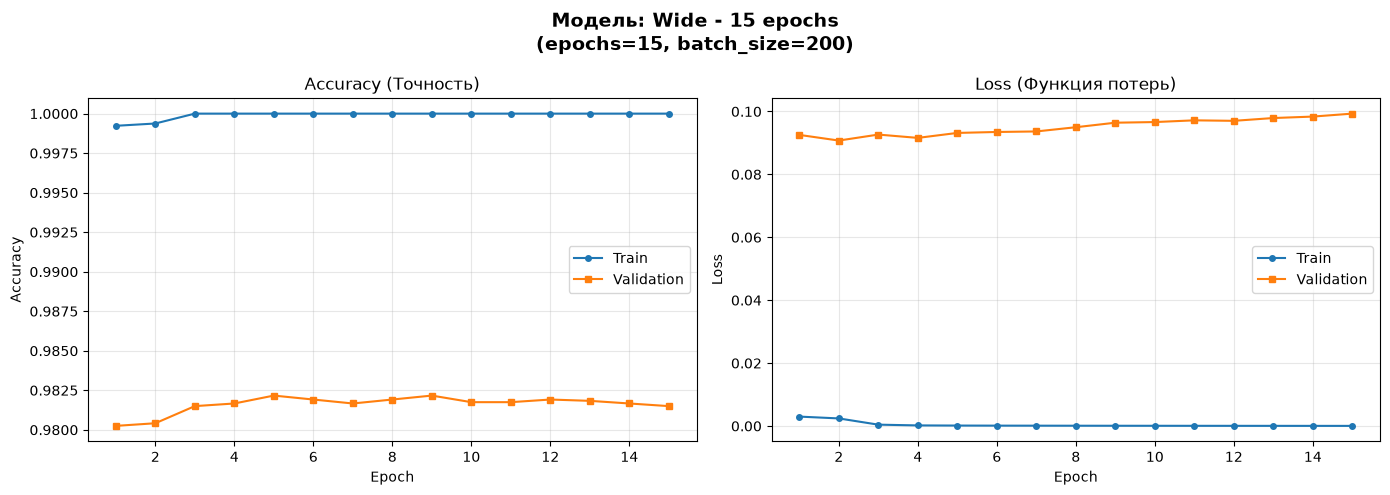


--- Обучение модели: Wide - 25 epochs (epochs=25, batch_size=200) ---
Epoch 1/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9994 - loss: 0.0024 - val_accuracy: 0.9797 - val_loss: 0.1025
Epoch 2/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9996 - loss: 0.0016 - val_accuracy: 0.9802 - val_loss: 0.1101
Epoch 3/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9993 - loss: 0.0026 - val_accuracy: 0.9763 - val_loss: 0.1331
Epoch 4/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9985 - loss: 0.0049 - val_accuracy: 0.9796 - val_loss: 0.1034
Epoch 5/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9999 - loss: 6.7173e-04 - val_accuracy: 0.9808 - val_loss: 0.1033
Epoch 6/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.4064e-04 - val_accuracy: 0.9810 - val_loss: 0.1003
Epoch 7/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 7.3187e-05 - val_accuracy: 0.9812 - val_loss: 0.1002
Epoch 8/25
240/240 ━━

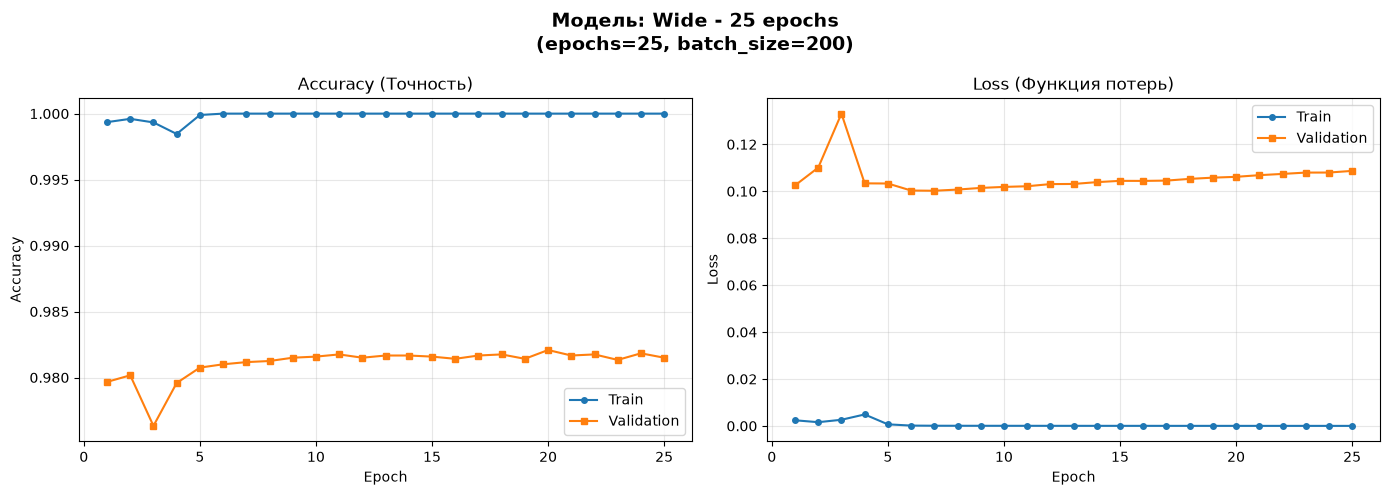


--- Обучение модели: Wide - 30 epochs (epochs=30, batch_size=200) ---
Epoch 1/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9994 - loss: 0.0018 - val_accuracy: 0.9804 - val_loss: 0.1205
Epoch 2/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9990 - loss: 0.0031 - val_accuracy: 0.9730 - val_loss: 0.1575
Epoch 3/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9990 - loss: 0.0030 - val_accuracy: 0.9802 - val_loss: 0.1198
Epoch 4/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9993 - loss: 0.0022 - val_accuracy: 0.9787 - val_loss: 0.1223
Epoch 5/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9999 - loss: 3.9893e-04 - val_accuracy: 0.9806 - val_loss: 0.1120
Epoch 6/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 6.5382e-05 - val_accuracy: 0.9810 - val_loss: 0.1111
Epoch 7/30
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 3.7548e-05 - val_accuracy: 0.9811 - val_loss: 0.1109
Epoch 8/30
240/240 ━━

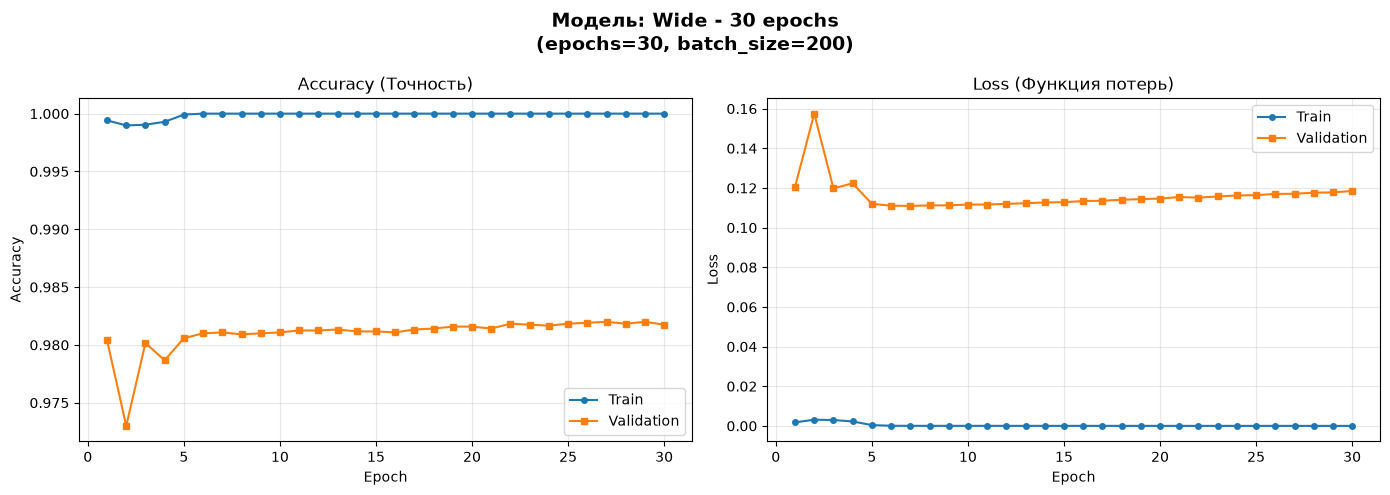


ЭКСПЕРИМЕНТ 3: Влияние размера мини-выборки (на примере Wide модели)

--- Обучение модели: Wide - bs=10 (epochs=20, batch_size=10) ---
Epoch 1/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.9883 - loss: 0.0432 - val_accuracy: 0.9745 - val_loss: 0.1456
Epoch 2/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.9891 - loss: 0.0402 - val_accuracy: 0.9727 - val_loss: 0.1695
Epoch 3/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.9906 - loss: 0.0330 - val_accuracy: 0.9725 - val_loss: 0.1700
Epoch 4/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.9904 - loss: 0.0372 - val_accuracy: 0.9772 - val_loss: 0.1608
Epoch 5/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.9924 - loss: 0.0269 - val_accuracy: 0.9753 - val_loss: 0.1689
Epoch 6/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.9929 - loss: 0.0271 - val_accuracy: 0.9744 - val_loss: 0.1922
Epoch 7/20
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - accuracy: 0.9933 - lo

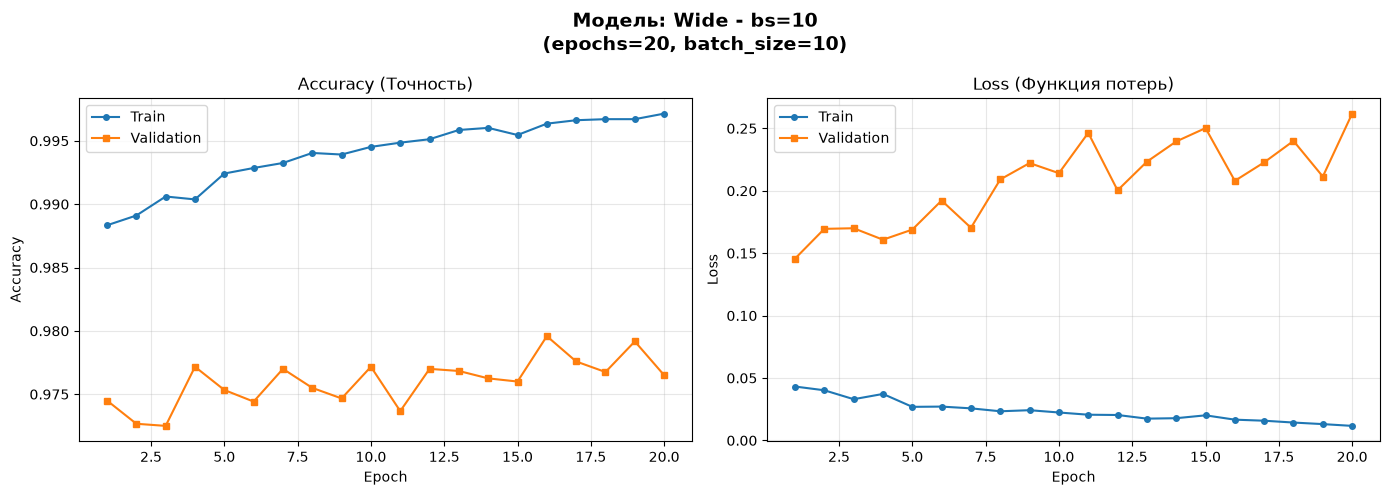


--- Обучение модели: Wide - bs=50 (epochs=20, batch_size=50) ---
Epoch 1/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9991 - loss: 0.0040 - val_accuracy: 0.9803 - val_loss: 0.2449
Epoch 2/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9756 - val_loss: 0.2937
Epoch 3/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9987 - loss: 0.0053 - val_accuracy: 0.9785 - val_loss: 0.2677
Epoch 4/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9993 - loss: 0.0025 - val_accuracy: 0.9811 - val_loss: 0.2297
Epoch 5/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9995 - loss: 0.0018 - val_accuracy: 0.9805 - val_loss: 0.2410
Epoch 6/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9994 - loss: 0.0024 - val_accuracy: 0.9797 - val_loss: 0.2361
Epoch 7/20
960/960 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9992 - loss: 0.0033 - val_accuracy: 0.9785 - val_loss: 0.2618
Epoch 8/20
960/960 ━━━━━━━━━━━━━━━━━━━

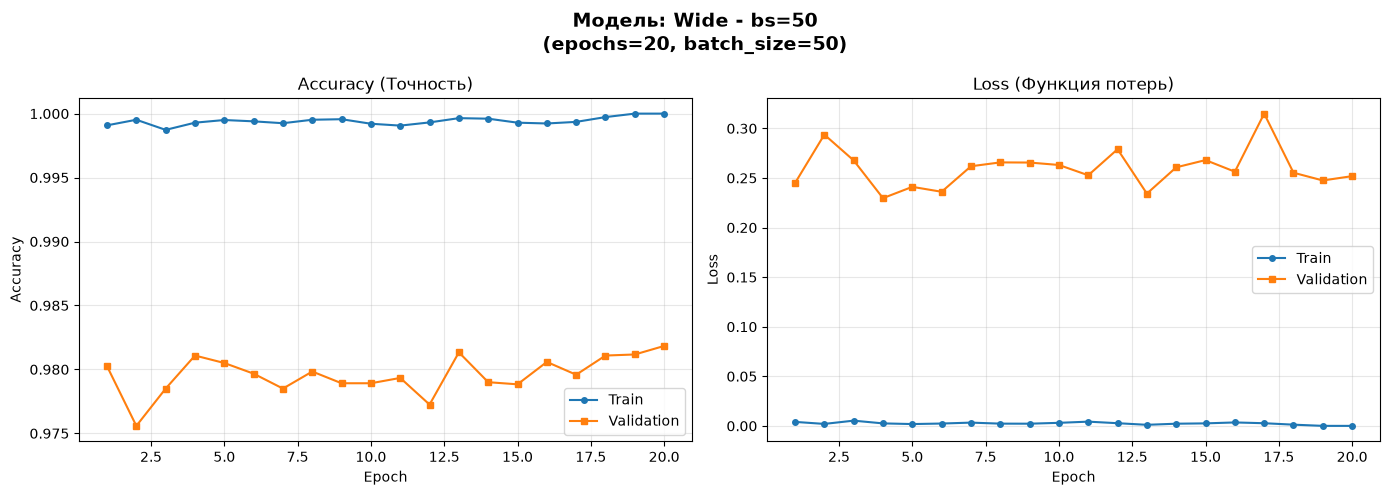


--- Обучение модели: Wide - bs=100 (epochs=20, batch_size=100) ---
Epoch 1/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9998 - loss: 6.3188e-04 - val_accuracy: 0.9803 - val_loss: 0.2729
Epoch 2/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9999 - loss: 4.0320e-04 - val_accuracy: 0.9812 - val_loss: 0.2768
Epoch 3/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 1.0000 - loss: 1.2400e-04 - val_accuracy: 0.9825 - val_loss: 0.2538
Epoch 4/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9786 - val_loss: 0.3069
Epoch 5/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9995 - loss: 0.0019 - val_accuracy: 0.9812 - val_loss: 0.2459
Epoch 6/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9997 - loss: 0.0015 - val_accuracy: 0.9800 - val_loss: 0.2682
Epoch 7/20
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9999 - loss: 1.7736e-04 - val_accuracy: 0.9813 - val_loss: 0.2581
Epoch 8/20
480/480 ━

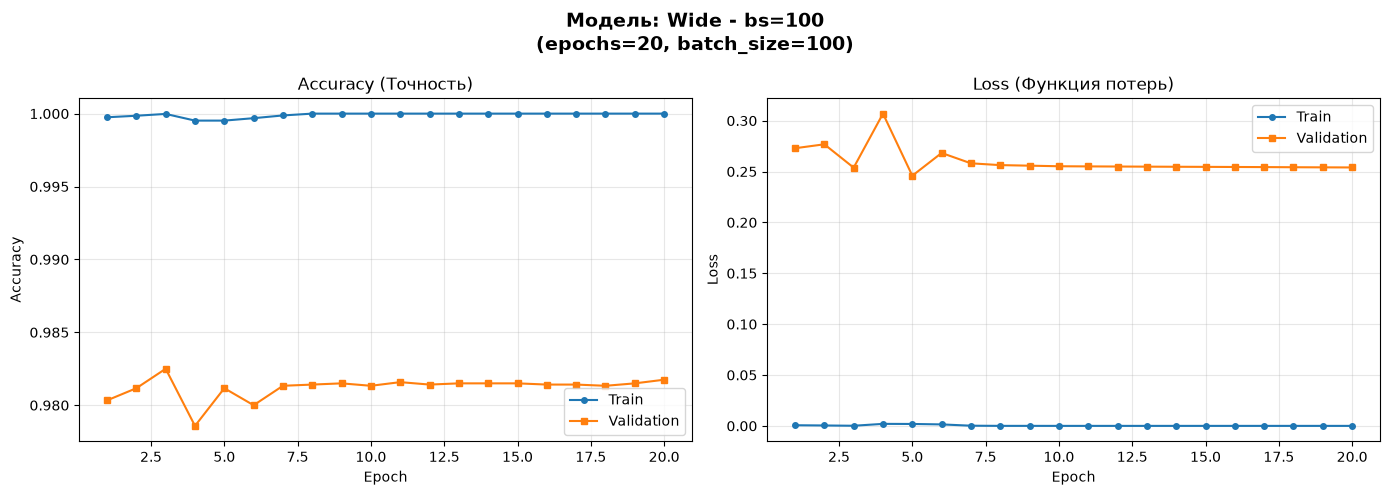


--- Обучение модели: Wide - bs=500 (epochs=20, batch_size=500) ---
Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 1.0000 - loss: 7.8240e-08 - val_accuracy: 0.9820 - val_loss: 0.2532
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 4.7209e-08 - val_accuracy: 0.9818 - val_loss: 0.2524
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 3.2584e-08 - val_accuracy: 0.9819 - val_loss: 0.2517
Epoch 4/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 2.4954e-08 - val_accuracy: 0.9818 - val_loss: 0.2513
Epoch 5/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 2.0705e-08 - val_accuracy: 0.9818 - val_loss: 0.2511
Epoch 6/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 1.7566e-08 - val_accuracy: 0.9820 - val_loss: 0.2508
Epoch 7/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 1.5234e-08 - val_accuracy: 0.9819 - val_loss: 0.2506
Epoch 8/20
96/96 ━━━━━

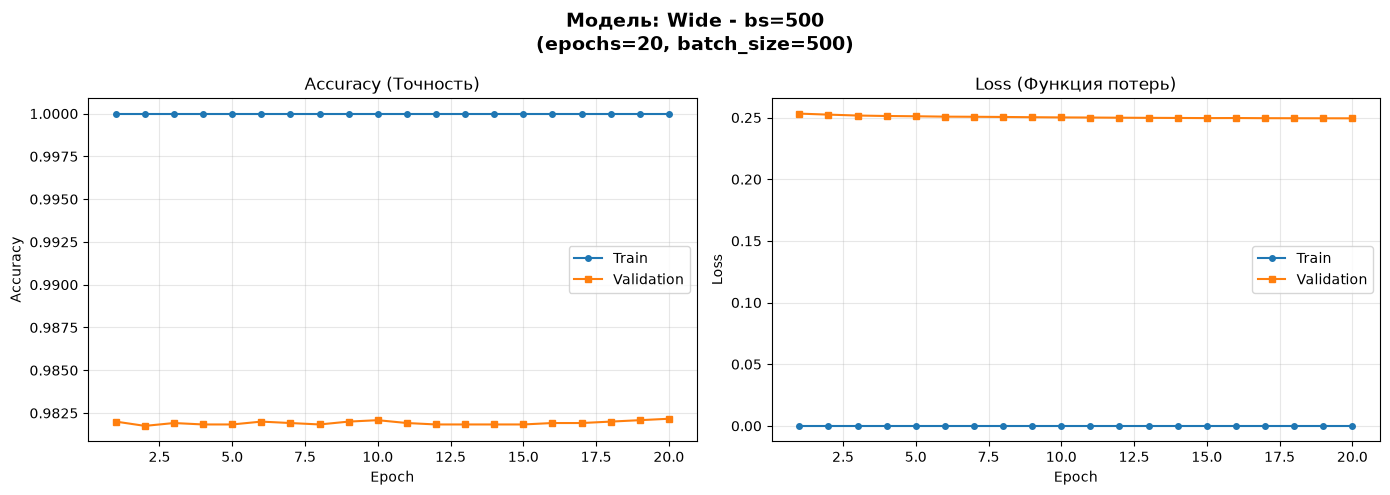


Все эксперименты завершены!


In [35]:
results = []

# Сравнение архитектур (базовые параметры)
print("ЭКСПЕРИМЕНТ 1: Сравнение архитектур (20 эпох, batch_size=200)")

for name, layers in models_to_test.items():
    model, history, loss, accuracy = build_and_train_model(name, layers, epochs=20, batch_size=200)

    results.append({
        "Experiment": "Architecture",
        "Model": name,
        "Epochs": 20,
        "Batch Size": 200,
        "Test Accuracy": accuracy,
        "Test Loss": loss,
        "Parameters": model.count_params()
    })

# Влияние количества эпох
print("\ЭКСПЕРИМЕНТ 2: Влияние количества эпох (на примере Wide модели)")
# Используем модель "Wide (1 hidden)" как основу
best_base_layers = models_to_test["Wide (1 hidden)"]
for epochs in [10, 15, 25, 30]:
    model, history, loss, accuracy = build_and_train_model(f"Wide - {epochs} epochs", best_base_layers, epochs=epochs, batch_size=200)
    results.append({
        "Experiment": "Epochs",
        "Model": f"Wide ({epochs} epochs)",
        "Epochs": epochs,
        "Batch Size": 200,
        "Test Accuracy": accuracy,
        "Test Loss": loss,
        "Parameters": model.count_params()
    })

# Влияние размера мини-выборки (batch_size)
print("\nЭКСПЕРИМЕНТ 3: Влияние размера мини-выборки (на примере Wide модели)")
for bs in [10, 50, 100, 500]:
    model, history, loss, accuracy = build_and_train_model(f"Wide - bs={bs}", best_base_layers, epochs=20, batch_size=bs)
    results.append({
        "Experiment": "Batch Size",
        "Model": f"Wide (bs={bs})",
        "Epochs": 20,
        "Batch Size": bs,
        "Test Accuracy": accuracy,
        "Test Loss": loss,
        "Parameters": model.count_params()
    })

print("\nВсе эксперименты завершены!")

In [36]:
# Создаем DataFrame для удобного отображения
df_results = pd.DataFrame(results)

# Форматируем для красивого вывода
df_results['Test Accuracy'] = df_results['Test Accuracy'].map('{:.4f}'.format)
df_results['Test Loss'] = df_results['Test Loss'].map('{:.4f}'.format)

# Выводим таблицу, отсортированную по точности
df_sorted = df_results.sort_values(by='Test Accuracy', ascending=False)

print("\n\n--- ИТОГОВАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ ---")
print(df_sorted.to_string(index=False))

print("\n\n--- ЛУЧШАЯ МОДЕЛЬ ---")
best_model_row = df_sorted.iloc[0]
print(f"Лучшая конфигурация: {best_model_row['Model']}")
print(f"Точность на тесте: {best_model_row['Test Accuracy']}")
print(f"Параметров: {best_model_row['Parameters']}")



--- ИТОГОВАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ ---
  Experiment              Model  Epochs  Batch Size Test Accuracy Test Loss  Parameters
      Epochs   Wide (25 epochs)      25         200        0.9838    0.0924      407050
      Epochs   Wide (30 epochs)      30         200        0.9837    0.0970      407050
  Batch Size      Wide (bs=500)      20         500        0.9830    0.2274      407050
Architecture Dropout (2 hidden)      20         200        0.9829    0.0720      535818
Architecture   Very Wide (1200)      20         200        0.9828    0.0644      954010
  Batch Size      Wide (bs=100)      20         100        0.9827    0.2301      407050
  Batch Size       Wide (bs=50)      20          50        0.9826    0.2406      407050
      Epochs   Wide (15 epochs)      15         200        0.9825    0.0838      407050
Architecture    Wide (1 hidden)      20         200        0.9824    0.0647      407050
Architecture    Deep (2 hidden)      20         200        0.9823    0.0832      